# LUR Results

Post-processing and visualization of land use regression results.


In [ ]:
import json

import contextily as cx
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from libpysal.weights import KNN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from focalpy import utils
from zurich_uhi_lur import regr_utils

sns.set_theme(style="ticks")

In [ ]:
# input data paths
stations_gdf_filepath = "../data/processed/stations.gpkg"
station_features_filepath = "../data/processed/stations-features.csv"
ts_df_filepath = "../data/processed/ts-df.csv"
grid_gdf_filepath = "../data/processed/regular-grid.gpkg"
grid_features_filepath = "../data/processed/grid-features.csv"

# LUR results
dst_results_filepath = "../data/processed/lur-results.csv"
dst_importance_filepath = "../data/processed/lur-importance.csv"
obs_pred_data_filepath = "../data/processed/lur-obs-pred.csv"
dst_baseline_moran_filepath = "../data/processed/baseline-moran.json"
grid_pred_filepath = "../data/processed/lur-grid-pred.nc"

# output figures
dst_scores_performance_filepath = "../reports/figures/lur-scores-performance.pdf"
dst_scores_rsa_filepath = "../reports/figures/lur-scores-rsa.pdf"
dst_rsa_filepath = "../reports/figures/lur-rsa.pdf"
dst_importance_fig_prefix = "../reports/figures/lur-importance"
dst_shap_filepath = "../data/processed/lur-shap.csv"
dst_maps_filepath = "../reports/figures/lur-maps.png"
dst_pca_filepath = "../reports/figures/lur-pca.pdf"
dst_pca_loadings_filepath = "../reports/figures/lur-pca-loadings.pdf"

# experiment settings (must match lur-model)
target_hour = 21
fracs = [0, 0.33, 0.66, 1]
seed = 0
n_reps = 5


# how to get model keys programmatically?
MODEL_KEYS = ["OLS", "GAM", "RF"]

## Load results


In [ ]:
results_df = pd.read_csv(dst_results_filepath)
importance_df = pd.read_csv(dst_importance_filepath)
shap_df = pd.read_csv(dst_shap_filepath)
obs_pred_df = pd.read_csv(obs_pred_data_filepath)

with open(dst_baseline_moran_filepath) as f:
    baseline_moran = json.load(f)

# Grid prediction maps come from the aggregated raster written by lur-model
# (mean/std over the LCS-subsampling reps), so no fitted pipelines are loaded here.
grid_pred_ds = xr.open_dataset(grid_pred_filepath)

print(
    f"Loaded {len(results_df)} result rows, "
    f"{len(importance_df)} importance rows, {len(shap_df)} shap rows"
)
print(f"Grid predictions: {dict(grid_pred_ds.sizes)}")

In [ ]:
station_features_gdf = regr_utils.get_site_features_gdf(
    station_features_filepath,
    stations_gdf_filepath,
)
aws_gdf = station_features_gdf[station_features_gdf["source"] == "AWS"]
lcs_gdf = station_features_gdf[station_features_gdf["source"] == "LCS"]

grid_features_gdf = regr_utils.get_site_features_gdf(
    grid_features_filepath,
    grid_gdf_filepath,
)

## Postprocessing

### Model performance and residual spatial autocorrelation

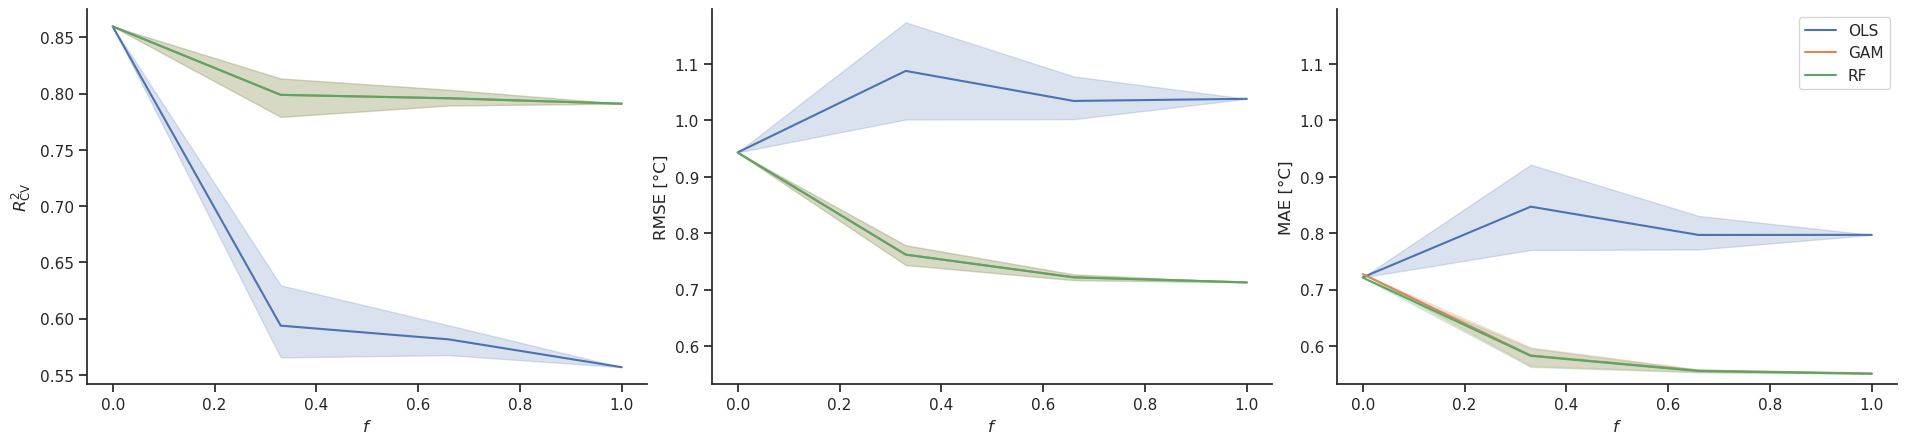

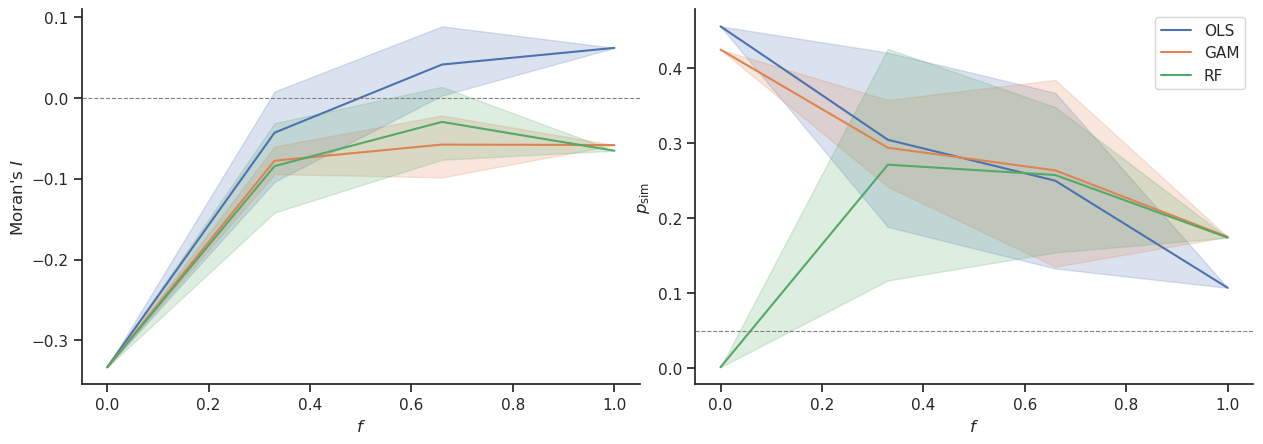

In [ ]:
figwidth, figheight = plt.rcParams["figure.figsize"]

# Per-rep RMSE and MAE from obs_pred_df so sns.lineplot can show CI across reps
error_df = (
    obs_pred_df.assign(
        sq_error=lambda d: (d["pred"] - d["obs"]) ** 2,
        abs_error=lambda d: (d["pred"] - d["obs"]).abs(),
    )
    .groupby(["model", "frac", "rep"])
    .agg(rmse=("sq_error", lambda x: np.sqrt(x.mean())), mae=("abs_error", "mean"))
    .reset_index()
)
plot_df = results_df.merge(error_df, on=["model", "frac", "rep"])

# Figure 1: predictive performance (R², RMSE, MAE)
perf_labels = {
    "r2_cv": r"$R^2_{\mathrm{CV}}$",
    "rmse": "RMSE [°C]",
    "mae": "MAE [°C]",
}
perf_long = plot_df.melt(
    id_vars=["model", "frac", "rep"],
    value_vars=list(perf_labels),
    var_name="metric",
)
g1 = sns.relplot(
    data=perf_long,
    kind="line",
    x="frac",
    y="value",
    hue="model",
    col="metric",
    col_order=list(perf_labels),
    facet_kws={"sharey": False},
    height=figheight,
    aspect=figwidth / figheight,
)
# sharey rmse/mae: capture both ylims first, then share and set union range
rmse_ylim = g1.axes_dict["rmse"].get_ylim()
mae_ylim = g1.axes_dict["mae"].get_ylim()
g1.axes_dict["mae"].sharey(g1.axes_dict["rmse"])
g1.axes_dict["rmse"].set_ylim(
    min(rmse_ylim[0], mae_ylim[0]),
    max(rmse_ylim[1], mae_ylim[1]),
)
handles = g1.legend.legend_handles
labels = [t.get_text() for t in g1.legend.get_texts()]
g1.legend.remove()
for metric, ax in g1.axes_dict.items():
    ax.set_title("")
    ax.set_xlabel("$f$")
    ax.set_ylabel(perf_labels[metric])
g1.axes_dict["mae"].legend(handles, labels, title="")
g1.savefig(dst_scores_performance_filepath, bbox_inches="tight")

# Figure 2: residual spatial autocorrelation (Moran's I, p-value)
rsa_labels = {
    "moran_I": r"Moran's $I$",
    "moran_p_sim": r"$p_{\mathrm{sim}}$",
}
rsa_reflines = {"moran_I": 0.0, "moran_p_sim": 0.05}
rsa_long = plot_df.melt(
    id_vars=["model", "frac", "rep"],
    value_vars=list(rsa_labels),
    var_name="metric",
)
g2 = sns.relplot(
    data=rsa_long,
    kind="line",
    x="frac",
    y="value",
    hue="model",
    col="metric",
    col_order=list(rsa_labels),
    facet_kws={"sharey": False},
    height=figheight,
    aspect=figwidth / figheight,
)
handles = g2.legend.legend_handles
labels = [t.get_text() for t in g2.legend.get_texts()]
g2.legend.remove()
for metric, ax in g2.axes_dict.items():
    ax.axhline(rsa_reflines[metric], color="0.5", linestyle="--", linewidth=0.8)
    ax.set_title("")
    ax.set_xlabel("$f$")
    ax.set_ylabel(rsa_labels[metric])
g2.axes_dict["moran_p_sim"].legend(handles, labels, title="")
g2.savefig(dst_scores_rsa_filepath, bbox_inches="tight")

### Spatial station coverage per LCS fraction

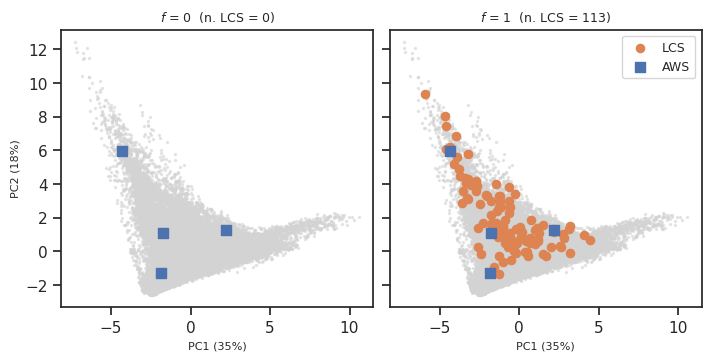

In [ ]:
X_grid = grid_features_gdf.drop(columns=["geometry", "source"], errors="ignore")

sample_per_frac = {
    fracs[0]: aws_gdf.drop(columns="source"),
    fracs[-1]: pd.concat([aws_gdf, lcs_gdf]).drop(columns="source"),
}
plot_fracs = [fracs[0], fracs[-1]]

# Fit PCA on the grid — defines the reference variance landscape
scaler_pca = StandardScaler()
X_grid_scaled = scaler_pca.fit_transform(X_grid.values)
pca = PCA(n_components=2)
grid_pcs = pca.fit_transform(X_grid_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(
    1,
    len(plot_fracs),
    figsize=(3.5 * len(plot_fracs), 3.5),
    constrained_layout=True,
    sharex=True,
    sharey=True,
)

for ax, frac in zip(axes, plot_fracs):
    ax.scatter(
        grid_pcs[:, 0],
        grid_pcs[:, 1],
        c="lightgrey",
        s=2,
        alpha=0.5,
        zorder=0,
        rasterized=True,
    )

    sample_gdf = sample_per_frac[frac]
    X_sample = sample_gdf.drop(columns="geometry").reindex(columns=X_grid.columns)
    sample_pcs = pca.transform(scaler_pca.transform(X_sample.values))

    aws_mask = sample_gdf.index.isin(aws_gdf.index)
    ax.scatter(
        sample_pcs[~aws_mask, 0],
        sample_pcs[~aws_mask, 1],
        c="C1",
        s=35,
        zorder=2,
        label="LCS",
    )
    ax.scatter(
        sample_pcs[aws_mask, 0],
        sample_pcs[aws_mask, 1],
        c="C0",
        marker="s",
        s=45,
        zorder=3,
        label="AWS",
    )

    n_lcs = (~aws_mask).sum()
    ax.set_title(f"$f$ = {frac}  (n. LCS = {n_lcs})", fontsize=9)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})", fontsize=8)

axes[0].set_ylabel(f"PC2 ({var_exp[1]:.0%})", fontsize=8)

axes[-1].legend(loc="best", fontsize=9)
fig.savefig(dst_pca_filepath, bbox_inches="tight")

#### PCA loadings

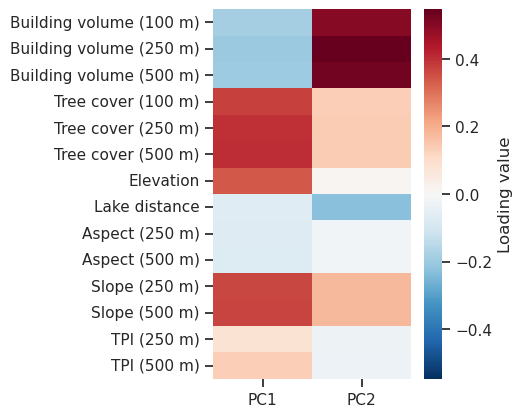

In [ ]:
figwidth, figheight = plt.rcParams["figure.figsize"]

pca_feature_labels = {
    "building_volume_sum_100": "Building volume (100 m)",
    "building_volume_sum_250": "Building volume (250 m)",
    "building_volume_sum_500": "Building volume (500 m)",
    "tree_sum_100": "Tree cover (100 m)",
    "tree_sum_250": "Tree cover (250 m)",
    "tree_sum_500": "Tree cover (500 m)",
    "elevation_0": "Elevation",
    "lake_distance_0": "Lake distance",
    "aspect_mean_250": "Aspect (250 m)",
    "aspect_mean_500": "Aspect (500 m)",
    "slope_mean_250": "Slope (250 m)",
    "slope_mean_500": "Slope (500 m)",
    "topographic_position_index_250": "TPI (250 m)",
    "topographic_position_index_500": "TPI (500 m)",
}

loading_df = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i + 1}" for i in range(pca.n_components_)],
    index=X_grid.columns,
).rename(index=pca_feature_labels)
max_abs = max(abs(loading_df.min().min()), loading_df.max().max())

fig, ax = plt.subplots(figsize=(0.5 * figwidth, figheight))
sns.heatmap(
    loading_df,
    cmap="RdBu_r",
    vmin=-max_abs,
    vmax=max_abs,
    cbar_kws={"label": "Loading value"},
    ax=ax,
)
fig.savefig(dst_pca_loadings_filepath, bbox_inches="tight")

### Observed vs predicted

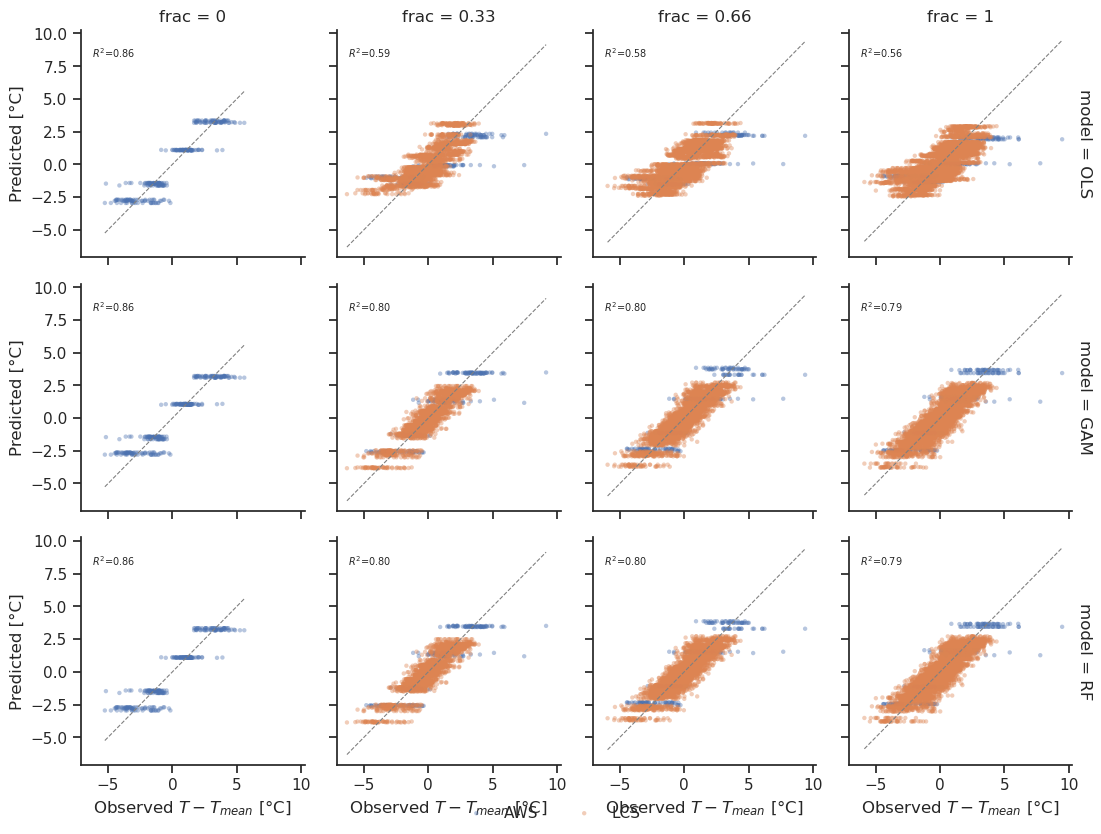

In [ ]:
# Show rep=0 for each frac: one representative sample, avoids overplotting multiple reps
plot_df = obs_pred_df[obs_pred_df["rep"] == 0].copy()

g = sns.FacetGrid(
    plot_df,
    row="model",
    col="frac",
    col_order=fracs,
    row_order=MODEL_KEYS,
    hue="source",
    palette={"AWS": "C0", "LCS": "C1"},
    height=2.8,
    aspect=1,
    sharex=True,
    sharey=True,
    margin_titles=True,
)
g.map(plt.scatter, "obs", "pred", alpha=0.4, s=10, edgecolors="none")

# identity line and per-panel R²_cv annotation
for (row_val, col_val), ax in g.axes_dict.items():
    sub = plot_df.query("model == @row_val and frac == @col_val")
    lo = min(sub["obs"].min(), sub["pred"].min())
    hi = max(sub["obs"].max(), sub["pred"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", linewidth=0.8, linestyle="--")
    r2_val = results_df.query("model == @row_val and frac == @col_val")["r2_cv"].mean()
    ax.text(
        0.05,
        0.93,
        f"$R^2$={r2_val:.2f}",
        transform=ax.transAxes,
        fontsize=7,
        va="top",
    )

g.set_axis_labels("Observed $T - T_{mean}$ [°C]", "Predicted [°C]")
g.add_legend(title="")
sns.move_legend(g, "lower center", ncol=2)

### Moran scatterplots (OOF residuals)


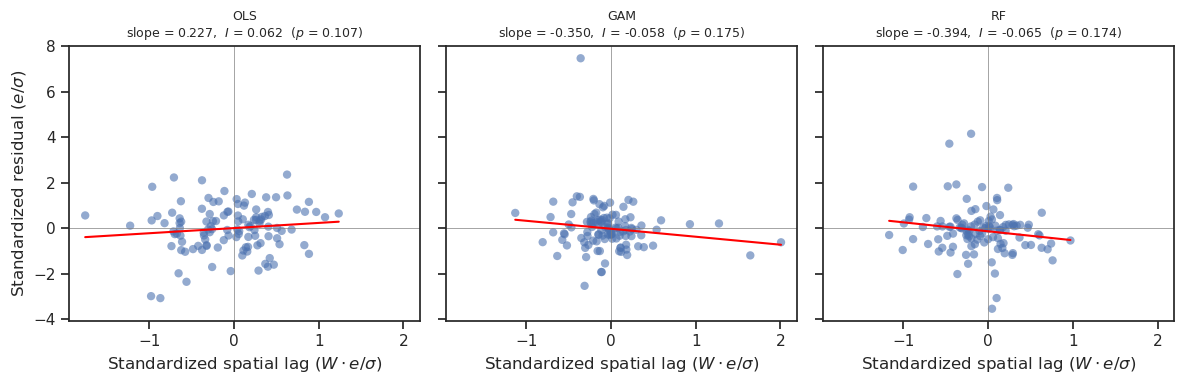

In [ ]:
# Use saved OOF residuals (rep=0, frac=1) so slopes and annotated I come from
# the same pipeline run. Station 534 was excluded from training in lur-model and
# is therefore absent from obs_pred_df; it is also excluded here from the KNN weights.
station_gdf_moran = pd.concat([aws_gdf, lcs_gdf]).drop(columns="source")
station_gdf_moran = station_gdf_moran[station_gdf_moran.index != "534"]
station_gser_moran = station_gdf_moran["geometry"]

coords = utils.as_coord_arr(station_gser_moran)
w_moran = KNN(coords, k=4)
w_moran.transform = "r"
station_ids = station_gser_moran.index  # order matches coords / spatial weights

moran_frac1 = (
    results_df[np.isclose(results_df["frac"], 1)]
    .groupby("model")[["moran_I", "moran_p_sim"]]
    .mean()
)


def _fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


fig, axes = plt.subplots(
    1, len(MODEL_KEYS), figsize=(12, 4), squeeze=False, sharey=True, sharex=True
)

for col, model_key in enumerate(MODEL_KEYS):
    ax = axes[0, col]

    op = obs_pred_df.query("model == @model_key and frac == 1 and rep == 0").copy()
    op["resid"] = op["obs"] - op["pred"]
    site_resid = op.groupby("station_id")["resid"].mean().reindex(station_ids).values
    # Standardise so all panels share the same scale and slope == Moran's I
    site_resid = site_resid / site_resid.std()
    w_lag = libpysal.weights.lag_spatial(w_moran, site_resid)

    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.scatter(w_lag, site_resid, alpha=0.6, edgecolors="none")

    z = np.polyfit(w_lag, site_resid, 1)
    p_poly = np.poly1d(z)
    xs = np.linspace(w_lag.min(), w_lag.max(), 100)
    ax.plot(xs, p_poly(xs), color="red", linewidth=1.5)

    I_val = moran_frac1.loc[model_key, "moran_I"]
    p_val = moran_frac1.loc[model_key, "moran_p_sim"]
    ax.set_title(
        f"{model_key}\nslope = {z[0]:.3f},  $I$ = {I_val:.3f}  ($p$ {_fmt_p(p_val)})",
        fontsize=9,
    )
    ax.set_xlabel("Standardized spatial lag ($W \\cdot e / \\sigma$)")
    if col == 0:
        ax.set_ylabel("Standardized residual ($e / \\sigma$)")

fig.tight_layout()
fig.savefig(dst_rsa_filepath, bbox_inches="tight")

### Feature importances

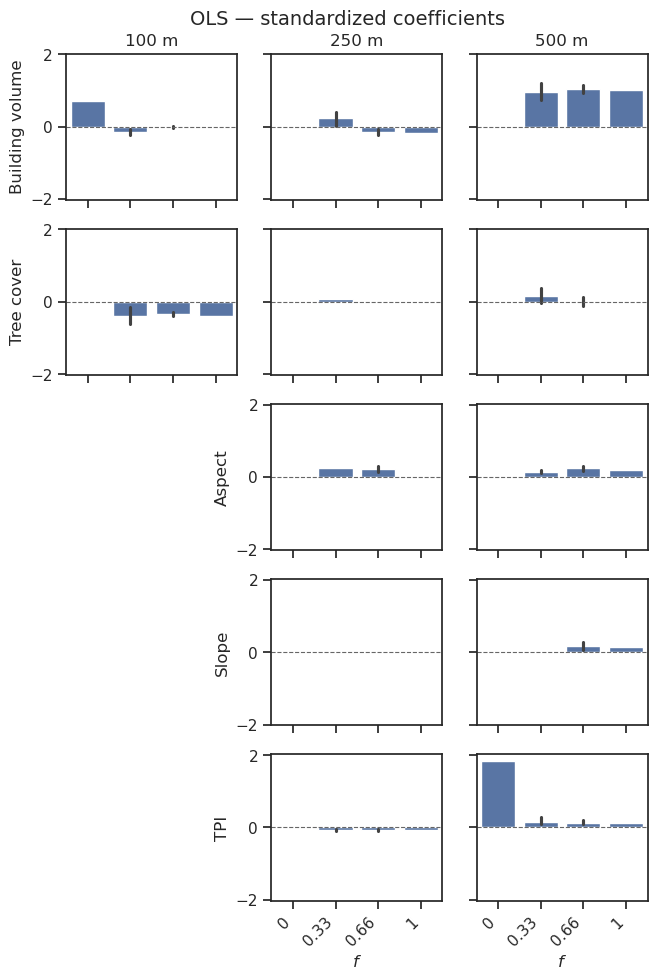

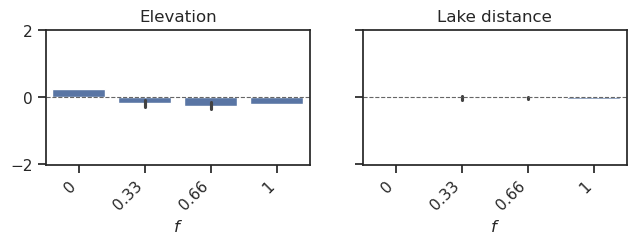

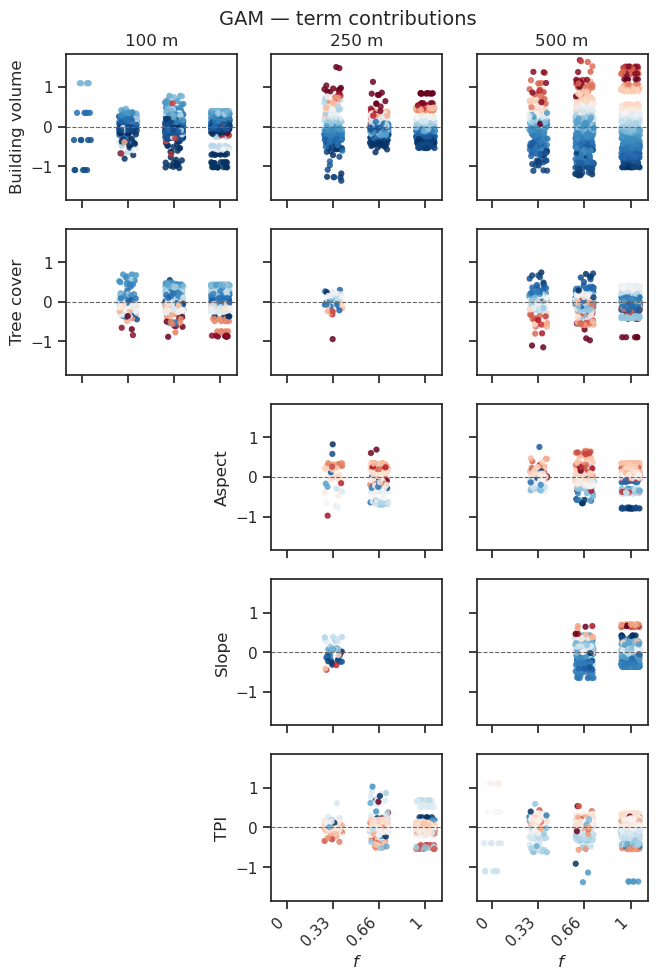

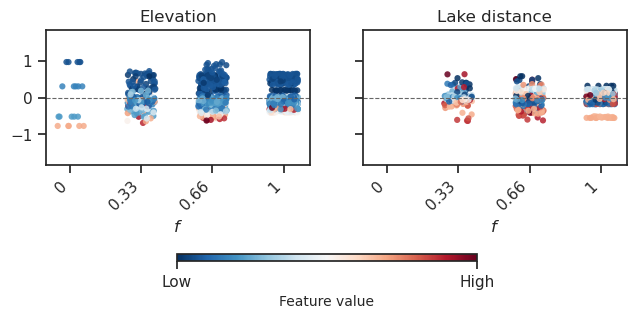

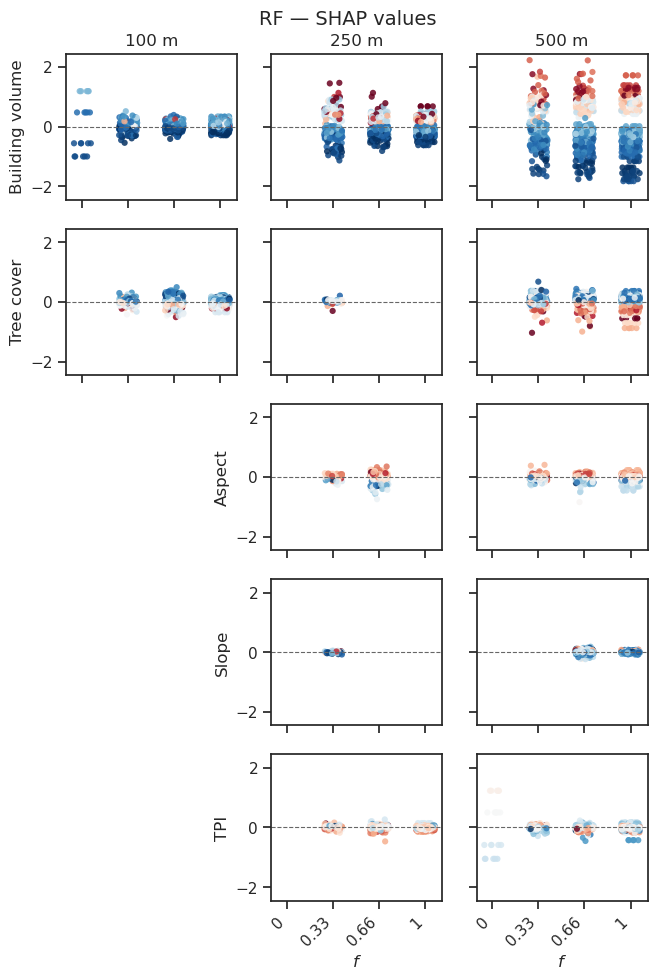

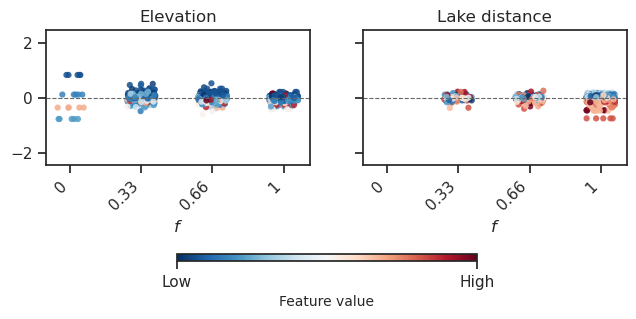

In [ ]:
SCALE_TO_COL = {100: 0, 250: 1, 500: 2}
multi_scale_groups = [
    (
        "Building volume",
        [
            "building_volume_sum_100",
            "building_volume_sum_250",
            "building_volume_sum_500",
        ],
    ),
    ("Tree cover", ["tree_sum_100", "tree_sum_250", "tree_sum_500"]),
    ("Aspect", ["aspect_mean_250", "aspect_mean_500"]),
    ("Slope", ["slope_mean_250", "slope_mean_500"]),
    (
        "TPI",
        ["topographic_position_index_250", "topographic_position_index_500"],
    ),
]
single_scale_groups = [
    ("Elevation", ["elevation_0"]),
    ("Lake distance", ["lake_distance_0"]),
]
frac_order = list(fracs)
MULTI_SCALE_FIGSIZE = (7.5, 11.0)
SINGLE_SCALE_FIGSIZE = (7.5, 3.0)
# Shared layout for single-scale panels so OLS and GAM/RF axes align vertically
SINGLE_SCALE_LAYOUT = dict(top=0.85, bottom=0.40)


def _compute_model_ylim(model_name, padding=0.1):
    """Symmetric ylim around 0 so positive/negative importances are equally visible."""
    data = importance_df.query("model == @model_name")["value"]
    max_abs = max(abs(data.min()), abs(data.max()))
    val = max_abs * (1 + padding)
    return (-val, val)


def _compute_shap_ylim(model_name, padding=0.1):
    data = shap_df.query("model == @model_name")["shap_value"]
    max_abs = max(abs(data.min()), abs(data.max()))
    return (-(max_abs * (1 + padding)), max_abs * (1 + padding))


# Per-feature value range for consistent beeswarm coloring across fracs
_feat_vranges = (
    shap_df.groupby("feature")["feature_value"]
    .agg(vmin="min", vmax="max")
    .to_dict("index")
)


def _barplot_feature(ax, plot_df, feature, color):
    sns.barplot(
        data=plot_df.query("feature == @feature"),
        x="frac",
        y="value",
        order=frac_order,
        estimator="mean",
        errorbar=("ci", 95),
        color=color,
        ax=ax,
    )
    ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)


def _beeswarm_feature(ax, plot_df, feature, ylim):
    data = plot_df.query("feature == @feature")
    if data.empty:
        ax.set_visible(False)
        return
    vmin = _feat_vranges.get(feature, {}).get("vmin", data["feature_value"].min())
    vmax = _feat_vranges.get(feature, {}).get("vmax", data["feature_value"].max())
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    rng = np.random.default_rng(42)
    for frac_idx, frac in enumerate(frac_order):
        sub = data[np.isclose(data["frac"], frac)]
        if sub.empty:
            continue
        colors = plt.cm.RdBu_r(norm(sub["feature_value"].values))
        x_jitter = rng.uniform(-0.2, 0.2, len(sub))
        ax.scatter(
            frac_idx + x_jitter,
            sub["shap_value"].values,
            c=colors,
            s=20,
            alpha=0.85,
            linewidths=0,
        )
    ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)
    ax.set_ylim(ylim)
    ax.set_xticks(range(len(frac_order)))
    ax.set_xticklabels([f"{f:g}" for f in frac_order], rotation=45, ha="right")


def _plot_multi_scale_importance(model_name, color, title, ylim):
    """Multi-scale figure: columns aligned by buffer distance (100/250/500 m).

    Features without a 100 m scale (Aspect, Slope, TPI) are pushed right so
    250 m always falls in col 1 and 500 m in col 2. The feature name is the
    ylabel on the leftmost visible column of each row. All axes share the same
    y range (symmetric around 0) so features can be compared directly.
    """
    plot_df = importance_df.query("model == @model_name").copy()
    n_rows = len(multi_scale_groups)
    n_cols = len(SCALE_TO_COL)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=MULTI_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.suptitle(title, fontsize=14, y=0.92)

    for row_idx, (group_label, group_features) in enumerate(multi_scale_groups):
        is_last_row = row_idx == n_rows - 1
        feat_by_scale = {int(f.rsplit("_", 1)[-1]): f for f in group_features}
        first_col = SCALE_TO_COL[min(feat_by_scale)]

        for scale, col_idx in SCALE_TO_COL.items():
            ax = axes[row_idx, col_idx]
            if scale not in feat_by_scale:
                ax.set_visible(False)
                continue

            _barplot_feature(ax, plot_df, feat_by_scale[scale], color)
            ax.set_ylim(ylim)
            ax.set_title(f"{scale} m" if row_idx == 0 else "", fontsize=12)

            if col_idx == first_col:
                ax.set_ylabel(group_label, fontsize=12)
            else:
                ax.set_ylabel("")
                ax.tick_params(labelleft=False)

            if is_last_row:
                ax.set_xlabel("$f$")
                ax.set_xticks(range(len(frac_order)))
                ax.set_xticklabels(
                    [f"{f:g}" for f in frac_order], rotation=45, ha="right"
                )
            else:
                ax.set_xlabel("")

    return fig


def _plot_single_scale_importance(model_name, color, title, ylim):
    """Single-scale figure: elevation and lake distance in one row, same ylim."""
    plot_df = importance_df.query("model == @model_name").copy()
    n_groups = len(single_scale_groups)

    fig, axes = plt.subplots(
        1,
        n_groups,
        figsize=SINGLE_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.subplots_adjust(**SINGLE_SCALE_LAYOUT)

    for col_idx, (group_label, group_features) in enumerate(single_scale_groups):
        ax = axes[0, col_idx]
        _barplot_feature(ax, plot_df, group_features[0], color)
        ax.set_ylim(ylim)
        ax.set_title(group_label, fontsize=12)
        ax.set_xlabel("$f$")
        ax.set_xticks(range(len(frac_order)))
        ax.set_xticklabels([f"{f:g}" for f in frac_order], rotation=45, ha="right")
        ax.set_ylabel("")
        if col_idx > 0:
            ax.tick_params(labelleft=False)

    return fig


def _plot_multi_scale_beeswarm(model_name, title, ylim):
    plot_df = shap_df.query("model == @model_name").copy()
    n_rows = len(multi_scale_groups)
    n_cols = len(SCALE_TO_COL)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=MULTI_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.suptitle(title, fontsize=14, y=0.92)

    for row_idx, (group_label, group_features) in enumerate(multi_scale_groups):
        feat_by_scale = {int(f.rsplit("_", 1)[-1]): f for f in group_features}
        first_col = SCALE_TO_COL[min(feat_by_scale)]
        is_last_row = row_idx == n_rows - 1

        for scale, col_idx in SCALE_TO_COL.items():
            ax = axes[row_idx, col_idx]
            if scale not in feat_by_scale:
                ax.set_visible(False)
                continue

            _beeswarm_feature(ax, plot_df, feat_by_scale[scale], ylim)
            ax.set_title(f"{scale} m" if row_idx == 0 else "", fontsize=12)

            if col_idx == first_col:
                ax.set_ylabel(group_label, fontsize=12)
            else:
                ax.set_ylabel("")
                ax.tick_params(labelleft=False)

            if is_last_row:
                ax.set_xlabel("$f$")
            else:
                ax.set_xlabel("")
                ax.set_xticklabels([])

    return fig


def _plot_single_scale_beeswarm(model_name, title, ylim):
    plot_df = shap_df.query("model == @model_name").copy()
    n_groups = len(single_scale_groups)

    fig, axes = plt.subplots(
        1,
        n_groups,
        figsize=SINGLE_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.subplots_adjust(**SINGLE_SCALE_LAYOUT)

    for col_idx, (group_label, group_features) in enumerate(single_scale_groups):
        ax = axes[0, col_idx]
        _beeswarm_feature(ax, plot_df, group_features[0], ylim)
        ax.set_title(group_label, fontsize=12)
        ax.set_xlabel("$f$")
        ax.set_ylabel("")
        if col_idx > 0:
            ax.tick_params(labelleft=False)

    cbar_ax = fig.add_axes([0.3, 0.08, 0.4, 0.025])
    sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(0, 1))
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
    cb.set_ticks([0, 1])
    cb.set_ticklabels(["Low", "High"])
    cb.set_label("Feature value", fontsize=10)

    return fig


# OLS: barplot, one figure per model (frac on x-axis)
ylim_ols = _compute_model_ylim("OLS")
for func, dst_fig_filepath, is_single in zip(
    [_plot_multi_scale_importance, _plot_single_scale_importance],
    [
        f"{dst_importance_fig_prefix}-OLS.pdf",
        f"{dst_importance_fig_prefix}-single-OLS.pdf",
    ],
    [False, True],
):
    fig = func("OLS", "C0", "OLS — standardized coefficients", ylim=ylim_ols)
    # Single-scale saved without tight crop so OLS and GAM/RF panels share the
    # exact same figure dimensions and axes positions for visual alignment.
    fig.savefig(dst_fig_filepath, **({} if is_single else {"bbox_inches": "tight"}))

# GAM, RF: beeswarm, one figure per model (frac groups on x-axis)
shap_model_configs = {
    "GAM": ("C2", "GAM — term contributions"),
    "RF": ("C1", "RF — SHAP values"),
}
for model_name, (color, title) in shap_model_configs.items():
    ylim = _compute_shap_ylim(model_name)
    for func, dst_fig_filepath, is_single in zip(
        [_plot_multi_scale_beeswarm, _plot_single_scale_beeswarm],
        [
            f"{dst_importance_fig_prefix}-{model_name}.pdf",
            f"{dst_importance_fig_prefix}-single-{model_name}.pdf",
        ],
        [False, True],
    ):
        fig = func(model_name, title, ylim)
        fig.savefig(dst_fig_filepath, **({} if is_single else {"bbox_inches": "tight"}))

### Grid prediction maps

In [ ]:
pred_label = r"$T-T_{mean}$' [$^{\circ}$C]"

pred_mean = grid_pred_ds["pred_mean"]
pred_std = grid_pred_ds["pred_std"]

x_range = float(pred_mean.x.max() - pred_mean.x.min())
y_range = float(pred_mean.y.max() - pred_mean.y.min())
map_aspect = abs(x_range / y_range)


def _draw_maps(da, *, cmap, vmin, vmax, cbar_label, dst_filepath=None):
    g = da.plot(
        col="frac",
        row="model",
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        aspect=map_aspect,
        cbar_kwargs={"shrink": 0.25, "pad": 0.03, "label": cbar_label},
    )
    for ax in g.axs.flat:
        ax.set_aspect("equal")
        ax.set_axis_off()
        cx.add_basemap(ax, crs=grid_features_gdf.crs, attribution=False)
    for ax, frac in zip(g.axs[0], da["frac"].values):
        ax.set_title(f"$f$ = {frac:.2f}")
    # model (row) labels on the left: hide xarray's default right-side labels and
    # annotate the leftmost column instead (set_axis_off() hides plain set_ylabel)
    for label in g.row_labels:
        if label is not None:
            label.set_visible(False)
    for ax, model_key in zip(g.axs[:, 0], da["model"].values):
        ax.annotate(
            model_key,
            xy=(-0.05, 0.5),
            xycoords="axes fraction",
            rotation=90,
            ha="right",
            va="center",
        )
    if dst_filepath is not None:
        g.fig.savefig(dst_filepath, dpi=300, bbox_inches="tight")
    return g


# Mean prediction across reps. Exclude the (OLS, f=0) panel — an unconstrained
# extrapolation with extreme values — from the shared color scale.
mask = ~((pred_mean.model == "OLS") & (pred_mean.frac == 0.0))
abs_max = float(np.abs(pred_mean.where(mask)).max())
_draw_maps(
    pred_mean,
    cmap="coolwarm",
    vmin=-abs_max,
    vmax=abs_max,
    cbar_label=pred_label,
    dst_filepath=dst_maps_filepath,
)

# Prediction spread (std) across reps = sensitivity to which LCS subset is drawn.
# Only intermediate fractions vary the sample; f=0 (AWS only) and f=1 (all LCS)
# have no subsampling, so they are omitted from the uncertainty maps.
sampling_fracs = [f for f in fracs if 0 < f < 1]
pred_std_sampling = pred_std.sel(frac=sampling_fracs)
std_max = float(pred_std_sampling.max())
_draw_maps(
    pred_std_sampling,
    cmap="magma",
    vmin=0,
    vmax=std_max,
    cbar_label=r"SD of $T-T_{mean}$' [$^{\circ}$C]",
)